# QFire Cusco — Fase 01: limpieza y control de calidad

**Propósito del proyecto:** preparar la planificación de entregas de recursos desde acopios hasta puntos de recepción de brigadas que atienden incendios forestales en Cusco.

Este notebook construye un **historial auditable de registros** para las fases siguientes. Los registros históricos no representan incendios simultáneamente activos. El inventario de donaciones, los pedidos, la red vial y los bloqueos se incorporan en las fases 02–06.

**Ámbito:** departamento de Cusco, años 2022 a 2026 inclusive.

La entrada es el CSV proporcionado por la usuaria y previamente depurado. Se conserva sin modificar en `data/raw/`. Su procedencia documentada es la [capa de incendios de MINAM](https://geoservidorperu.minam.gob.pe/arcgis/rest/services/CFOI_Dashboard_mensuales_pruebas/MapServer/0).

| Entrada | Salida principal |
|---|---|
| `data/raw/incendios_Cusco_2022_2026.csv` | `data/processed/incendios_historicos.csv` |

Para ejecutar, abrir **la carpeta completa del proyecto**, instalar `requirements.txt` y correr las celdas en orden. El código compartido está en `src/qfire_cusco/cleaning.py`.


## 0. Criterios de preparación

1. El archivo de entrada es inmutable; su huella SHA-256 permite comprobarlo.
2. Los identificadores se leen como texto para conservar ceros iniciales.
3. Se normalizan espacios y fechas, preservando los valores originales relevantes y la procedencia.
4. Solo se eliminan duplicados exactos de contenido normalizado. Coincidir en fecha o coordenadas no basta para eliminar un registro.
5. Los problemas de fechas, confirmación o coordenadas se marcan. Las filas siguen disponibles en el historial para revisión.
6. Una cobertura reportada como cero no se interpreta automáticamente como magnitud confirmada cero. No se supone que la unidad de `COB_AFECTA` sea hectáreas.
7. Los puntos del historial son referencias del incidente; la fase 02 definirá por separado los puntos donde recibirán los recursos.


In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value.to_string(index=False) if isinstance(value, pd.DataFrame) else value)

def locate_project_root():
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / 'src/qfire_cusco/cleaning.py').is_file() and (candidate / 'data/raw').is_dir():
            return candidate
    raise FileNotFoundError(
        'Abra la carpeta completa qfire-cusco. El notebook requiere las carpetas src y data/raw del paquete.'
    )

ROOT = locate_project_root()
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from qfire_cusco.cleaning import CleaningConfig, clean_source, export_result, read_source, sha256_file

pd.set_option('display.max_columns', 12)
pd.set_option('display.max_colwidth', 80)


## 1. Configuración

El rango temporal se aplica al año reportado y se comprueba contra la fecha de emergencia. El filtro territorial usa el departamento completo, sin restringir provincias.

`COVERAGE_UNIT = None` conserva el estado **unidad no confirmada**. Solo se debe cambiar por `ha` o `m2` cuando una fuente documental permita confirmar esa interpretación. Esta fase no rellena magnitudes faltantes con valores simulados.


In [2]:
INPUT_PATH = ROOT / 'data/raw/incendios_Cusco_2022_2026.csv'
DEPARTMENT = 'CUSCO'
YEAR_START, YEAR_END = 2022, 2026
COVERAGE_UNIT = None

config = CleaningConfig(
    department=DEPARTMENT, year_start=YEAR_START, year_end=YEAR_END,
    coverage_unit=COVERAGE_UNIT,
)
assert INPUT_PATH.is_file(), f'Falta el archivo: {INPUT_PATH.name}'
RAW_HASH_BEFORE = sha256_file(INPUT_PATH)
print(f'Entrada: {INPUT_PATH.relative_to(ROOT)}')
print(f'Ámbito: {DEPARTMENT}, {YEAR_START}–{YEAR_END}')
print(f'SHA-256: {RAW_HASH_BEFORE}')


Entrada: data/raw/incendios_Cusco_2022_2026.csv
Ámbito: CUSCO, 2022–2026
SHA-256: 7f76fb11460439e136c31439dd78c732882fa289f7af11cbea0f4750e97f9716


## 2. Lectura y reconocimiento de la entrada

El archivo se lee en UTF-8 con BOM y las columnas ingresan como texto. El texto `NA`, si estuviera presente en un nombre, no se borra como si fuera un valor faltante. No se solicitan datos externos al ejecutar este notebook.


In [3]:
raw = read_source(INPUT_PATH)
print(f'Filas de entrada: {len(raw):,}')
print(f'Columnas de entrada: {len(raw.columns)}')
display(raw[['OBJECTID_12', 'NOMBPROV', 'NOMBDIST', 'FEC_EMERGE', 'ANIO', 'INCENDIO']].head(6))


Filas de entrada: 3,365
Columnas de entrada: 25


,OBJECTID_12,NOMBPROV,NOMBDIST,FEC_EMERGE,ANIO,INCENDIO
0,109610,PAUCARTAMBO,CHALLABAMBA,26/08/2026,2026,SI
1,109607,PAUCARTAMBO,KOSÑIPATA,26/08/2026,2026,SI
2,109604,PAUCARTAMBO,CHALLABAMBA,26/08/2026,2026,SI
3,109600,PAUCARTAMBO,PAUCARTAMBO,26/08/2026,2026,SI
4,109595,ANTA,ANCAHUASI,26/08/2026,2026,SI
5,109545,CHUMBIVILCAS,CHAMACA,26/08/2026,2026,SI


## 3. Normalización, ámbito y duplicados

Las funciones reutilizables normalizan texto, filtran el ámbito, conservan las referencias de origen y construyen `INCENDIO_ID`.

Un identificador de origen que se repita con contenido diferente no se descarta: sus registros reciben identificadores derivados distintos y una observación de revisión. Los duplicados exactos se consolidan conservando sus IDs y filas de procedencia.


In [4]:
result = clean_source(INPUT_PATH, config)
historical = result.historical
summary = result.summary

reconciliation = pd.DataFrame([
    ['Entrada', summary['filas_entrada']],
    ['Fuera del ámbito', summary['filas_fuera_de_ambito']],
    ['Duplicados exactos retirados en esta ejecución', summary['duplicados_exactos_retirados']],
    ['Historial resultante', summary['registros_historicos']],
], columns=['Concepto', 'Registros'])
display(reconciliation)
assert summary['filas_entrada'] == (
    summary['filas_fuera_de_ambito'] + summary['duplicados_exactos_retirados'] + len(historical)
)
assert historical['INCENDIO_ID'].is_unique
display(historical[['INCENDIO_ID', 'PROVINCIA', 'DISTRITO', 'FECHA_INICIO', 'ANIO']].head(6))


,Concepto,Registros
0,Entrada,3365
1,Fuera del ámbito,0
2,Duplicados exactos retirados en esta ejecución,0
3,Historial resultante,3365


,INCENDIO_ID,PROVINCIA,DISTRITO,FECHA_INICIO,ANIO
0,MINAM-109537,CANAS,YANAOCA,2026-08-26,2026
1,MINAM-109543,CANCHIS,SAN PABLO,2026-08-26,2026
2,MINAM-109545,CHUMBIVILCAS,CHAMACA,2026-08-26,2026
3,MINAM-109595,ANTA,ANCAHUASI,2026-08-26,2026
4,MINAM-109600,PAUCARTAMBO,PAUCARTAMBO,2026-08-26,2026
5,MINAM-109604,PAUCARTAMBO,CHALLABAMBA,2026-08-26,2026


## 4. Fechas y cobertura temporal

Las fechas válidas se guardan como `AAAA-MM-DD`. Los textos originales permanecen disponibles. Un valor de término como `1` se marca como inválido; no se transforma en una fecha ni en una prueba de que el incendio sigue activo.

La fecha máxima del archivo describe el último registro presente, no la fecha de actualización garantizada del servicio ni la cobertura completa de 2026.


In [5]:
print(f"Rango de fechas de emergencia: {summary['fecha_minima']} a {summary['fecha_maxima']}")
by_year = historical.groupby('ANIO').size().rename('REGISTROS').reset_index()
display(by_year)
date_observations = historical.loc[
    historical['OBSERVACIONES_CALIDAD'].str.contains('fecha_|anio_no_coincide|termino_anterior', regex=True),
    ['INCENDIO_ID', 'FEC_EMERGE_ORIGINAL', 'FEC_TERMIN_ORIGINAL', 'FECHA_INICIO', 'FECHA_TERMINO', 'OBSERVACIONES_CALIDAD'],
]
print(f'Registros con observaciones temporales: {len(date_observations)}')
display(date_observations.head(6))


Rango de fechas de emergencia: 2022-01-01 a 2026-08-26


,ANIO,REGISTROS
0,2022,1291
1,2023,590
2,2024,669
3,2025,722
4,2026,93


Registros con observaciones temporales: 23


,INCENDIO_ID,FEC_EMERGE_ORIGINAL,FEC_TERMIN_ORIGINAL,FECHA_INICIO,FECHA_TERMINO,OBSERVACIONES_CALIDAD
865,MINAM-99727,28/10/2024,1,2024-10-28,,fecha_termino_invalida;unidad_cobertura_no_confirmada
873,MINAM-99740,27/10/2024,1,2024-10-27,,fecha_termino_invalida;cobertura_reportada_cero_sin_magnitud_confirmada
919,MINAM-99754,20/10/2024,1,2024-10-20,,fecha_termino_invalida;unidad_cobertura_no_confirmada
931,MINAM-99792,20/10/2024,1,2024-10-20,,fecha_termino_invalida;cobertura_reportada_cero_sin_magnitud_confirmada
941,MINAM-99827,20/10/2024,1,2024-10-20,,fecha_termino_invalida;cobertura_reportada_cero_sin_magnitud_confirmada
947,MINAM-99860,20/10/2024,1,2024-10-20,,fecha_termino_invalida;cobertura_reportada_cero_sin_magnitud_confirmada


## 5. Coordenadas, confirmación y selección para EDA

`APTO_MAPEO` requiere coordenadas plausibles para Perú, confirmación y una fecha de inicio coherente con el año reportado. El control de coordenadas no reemplaza una intersección con la frontera de Cusco ni una comprobación de acceso por carretera.

Los registros no aptos quedan en el historial y en el reporte. No se incorporan a la vista que servirá como preselección para el EDA.


In [6]:
print(f"Aptos para iniciar el EDA: {summary['aptos_para_mapeo']:,}")
print(f"Pendientes de revisión antes del mapeo: {summary['no_aptos_para_mapeo']:,}")
display(historical.loc[~historical['APTO_MAPEO'], [
    'INCENDIO_ID', 'PROVINCIA', 'DISTRITO', 'CONFIRMACION_ORIGINAL', 'OBSERVACIONES_CALIDAD'
]].head(10))


Aptos para iniciar el EDA: 3,363
Pendientes de revisión antes del mapeo: 2


,INCENDIO_ID,PROVINCIA,DISTRITO,CONFIRMACION_ORIGINAL,OBSERVACIONES_CALIDAD
90,MINAM-109181,LA CONVENCION,QUELLOUNO,NO VERIFICADO,incendio_no_verificado;sin_localidad;cobertura_reportada_cero_sin_magnitud_c...
91,MINAM-109178,QUISPICANCHI,OROPESA,NO VERIFICADO,incendio_no_verificado;sin_localidad;cobertura_reportada_cero_sin_magnitud_c...


## 6. Cobertura afectada y magnitud

El archivo suministrado contiene muchos ceros en `COB_AFECTA`. Se conserva el texto original y su valor numérico; **no se inventan superficies ni se asigna una unidad automáticamente**.

`AREA_HA` solo se calcula para valores positivos cuando `COVERAGE_UNIT` haya sido confirmada documentalmente. Mientras siga vacía, la siguiente fase no deberá clasificar esos registros como incendios de cero hectáreas. Los escenarios operativos tendrán magnitudes reportadas o simuladas con su procedencia.


In [7]:
magnitude = pd.DataFrame([
    ['Cobertura reportada como cero', summary['cobertura_cero']],
    ['Cobertura positiva con unidad sin confirmar', summary['cobertura_positiva_sin_confirmar_unidad']],
    ['Área en hectáreas con unidad confirmada', summary['area_ha_verificada']],
], columns=['Condición', 'Registros'])
display(magnitude)
display(historical.loc[historical['COB_AFECTA_VALOR'].gt(0), [
    'INCENDIO_ID', 'COB_AFECTA_ORIGINAL', 'COB_AFECTA_VALOR', 'UNIDAD_COBERTURA', 'AREA_HA'
]].head(6))


,Condición,Registros
0,Cobertura reportada como cero,3136
1,Cobertura positiva con unidad sin confirmar,229
2,Área en hectáreas con unidad confirmada,0


,INCENDIO_ID,COB_AFECTA_ORIGINAL,COB_AFECTA_VALOR,UNIDAD_COBERTURA,AREA_HA
82,MINAM-54612,12.0,12.0,NO_CONFIRMADA,<NA>
83,MINAM-54607,10.0,10.0,NO_CONFIRMADA,<NA>
84,MINAM-54610,25.0,25.0,NO_CONFIRMADA,<NA>
86,MINAM-54613,3.0,3.0,NO_CONFIRMADA,<NA>
88,MINAM-109201,53.0,53.0,NO_CONFIRMADA,<NA>
89,MINAM-109200,17.0,17.0,NO_CONFIRMADA,<NA>


## 7. Reporte de calidad

Cada regla indica el número de registros afectados, el denominador y el porcentaje. `WARN` identifica un atributo pendiente de interpretación o revisión. Un registro puede tener varias observaciones, por lo que los recuentos de reglas no deben sumarse como si fueran filas diferentes.


In [8]:
display(result.quality)
print(f"Provincias representadas en esta selección: {summary['provincias_representadas']}")
print(f"Registros con alguna observación: {historical['OBSERVACIONES_CALIDAD'].ne('').sum():,}")


,REGLA,N_AFECTADAS,DENOMINADOR,PORCENTAJE,SEVERIDAD
0,filas_fuera_de_ambito,0,3365,0.00,INFO
1,duplicados_exactos_retirados,0,3365,0.00,INFO
2,sin_id_original,0,3365,0.00,WARN
3,id_original_con_contenidos_distintos,0,3365,0.00,WARN
4,fecha_inicio_invalida_o_ausente,0,3365,0.00,WARN
5,anio_no_coincide_con_fecha,0,3365,0.00,WARN
6,fecha_termino_invalida,23,3365,0.68,WARN
7,termino_anterior_al_inicio,0,3365,0.00,WARN
8,coordenadas_invalidas_o_fuera_de_peru,0,3365,0.00,WARN
9,incendio_no_verificado,2,3365,0.06,WARN


Provincias representadas en esta selección: 13
Registros con alguna observación: 3,365


## 8. Resumen descriptivo del historial

Los gráficos representan **registros presentes en este archivo**. Las diferencias entre años no se interpretan como tasas de riesgo: 2026 tiene una cobertura temporal parcial y pueden existir cambios de reporte o de disponibilidad entre períodos.


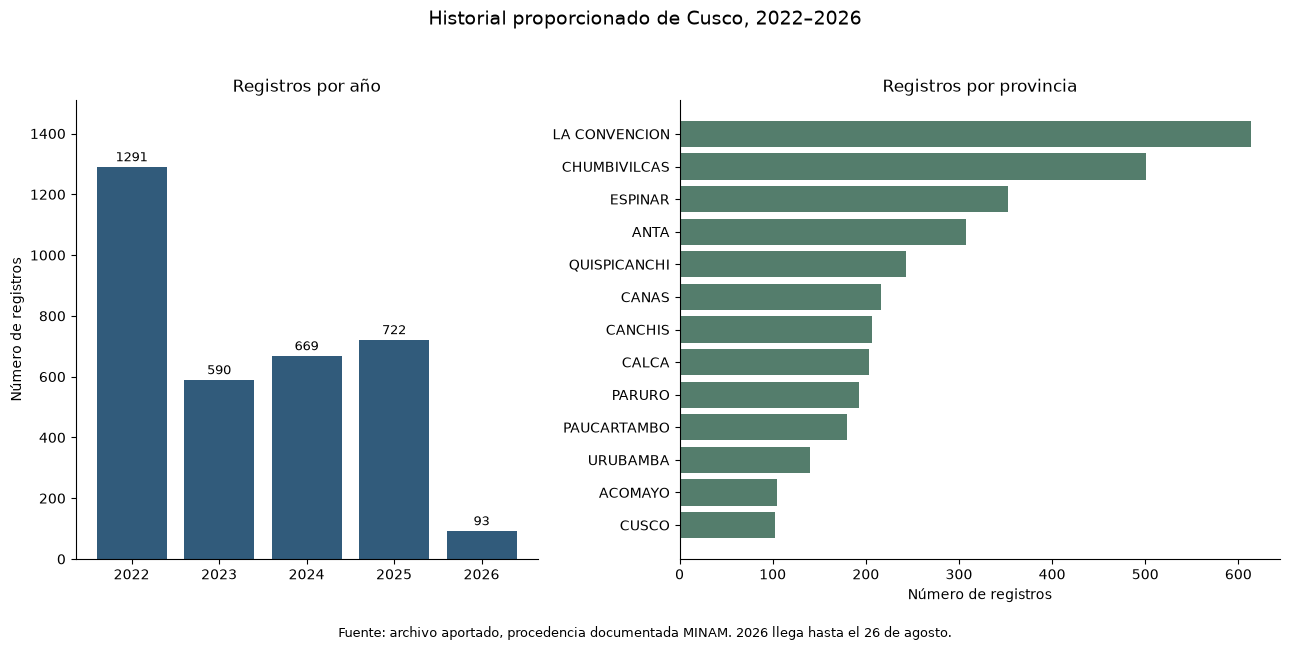

In [9]:
FIGURES_DIR = ROOT / 'outputs/figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
by_province = historical.groupby('PROVINCIA').size().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), gridspec_kw={'width_ratios': [1, 1.3]})
axes[0].bar(by_year['ANIO'].astype(str), by_year['REGISTROS'], color='#315b7b')
axes[0].set_title('Registros por año')
axes[0].set_ylabel('Número de registros')
for i, value in enumerate(by_year['REGISTROS']):
    axes[0].text(i, value + 18, str(value), ha='center', fontsize=9)
axes[0].set_ylim(0, by_year['REGISTROS'].max() * 1.17)
axes[1].barh(by_province.index, by_province.values, color='#547d6c')
axes[1].set_title('Registros por provincia')
axes[1].set_xlabel('Número de registros')
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Historial proporcionado de Cusco, 2022–2026', fontsize=14)
fig.text(0.5, 0.015, 'Fuente: archivo aportado, procedencia documentada MINAM. 2026 llega hasta el 26 de agosto.', ha='center', fontsize=9)
fig.tight_layout(rect=[0, 0.045, 1, 0.95])
FIGURE_PATH = FIGURES_DIR / '01_historial_por_anio_provincia.png'
fig.savefig(FIGURE_PATH, dpi=150, bbox_inches='tight')
plt.show()


## 9. Exportación reproducible

Los CSV se escriben en UTF-8 con BOM para facilitar su apertura en Excel. El historial completo y las vistas de mapeo y observaciones se guardan por separado. Son vistas relacionadas: no deben concatenarse como si fueran nuevos incidentes.

Los manifiestos y resúmenes se guardan en `outputs/reports/`. Los registros fuera del ámbito o duplicados retirados conservan un archivo con encabezados aunque no haya filas afectadas.


In [10]:
exported = export_result(result, ROOT)
display(pd.DataFrame([
    {'ARCHIVO': str(path.relative_to(ROOT)), 'BYTES': path.stat().st_size}
    for path in exported.values()
]))


,ARCHIVO,BYTES
0,data/processed/incendios_historicos.csv,1684436
1,data/processed/incendios_para_mapeo.csv,1683291
2,data/processed/incendios_con_observaciones.csv,1684436
3,data/processed/registros_fuera_de_ambito.csv,299
4,data/processed/duplicados_retirados.csv,67
5,data/processed/data_quality_report.csv,819
6,outputs/reports/source_manifest.json,946
7,outputs/reports/limpieza_resumen.json,546


## 10. Verificación de la salida guardada

Se reconcilian los conteos, la unicidad de IDs y el ámbito. También se verifica que la entrada siga teniendo la misma huella. Los problemas de la fuente permanecen visibles para las siguientes fases.


In [11]:
saved = pd.read_csv(exported['incendios_historicos.csv'], dtype=str, keep_default_na=False, encoding='utf-8-sig')
mapped = pd.read_csv(exported['incendios_para_mapeo.csv'], dtype=str, keep_default_na=False, encoding='utf-8-sig')
assert len(saved) == len(historical)
assert saved['INCENDIO_ID'].is_unique
assert saved['DEPARTAMENTO'].eq(DEPARTMENT).all()
assert saved['ANIO'].astype(int).between(YEAR_START, YEAR_END).all()
assert len(mapped) == summary['aptos_para_mapeo']
assert mapped['APTO_MAPEO'].eq('True').all()
assert sha256_file(INPUT_PATH) == RAW_HASH_BEFORE
if COVERAGE_UNIT is None:
    assert saved['AREA_HA'].eq('').all()
print('Verificaciones completadas: conteos, IDs, ámbito, exportación y entrada sin cambios.')
print(json.dumps(summary, ensure_ascii=False, indent=2))


Verificaciones completadas: conteos, IDs, ámbito, exportación y entrada sin cambios.
{
  "filas_entrada": 3365,
  "filas_en_ambito_antes_deduplicacion": 3365,
  "registros_historicos": 3365,
  "duplicados_exactos_retirados": 0,
  "filas_fuera_de_ambito": 0,
  "aptos_para_mapeo": 3363,
  "no_aptos_para_mapeo": 2,
  "fecha_minima": "2022-01-01",
  "fecha_maxima": "2026-08-26",
  "registros_por_anio": {
    "2022": 1291,
    "2023": 590,
    "2024": 669,
    "2025": 722,
    "2026": 93
  },
  "provincias_representadas": 13,
  "cobertura_cero": 3136,
  "cobertura_positiva_sin_confirmar_unidad": 229,
  "area_ha_verificada": 0
}


## Resultado y siguiente fase

La salida principal es **`data/processed/incendios_historicos.csv`**. Para iniciar el EDA, se dispone de **`incendios_para_mapeo.csv`**, con los controles mínimos declarados en esta fase.

La fase 02 incorporará la red vial, el centro de acopio y los puntos de recepción de brigadas. Una coordenada histórica del incendio no se convierte automáticamente en un punto receptor accesible.

La magnitud sigue requiriendo una unidad verificada o un valor de escenario identificado. El cierre temporal de una emergencia, cuando falta o es inválido, tampoco se infiere.

**Fases posteriores:** inventario y solicitudes; asignación y rutas; benchmark QAOA; bloqueos y replanificación. La arquitectura y el diccionario completos están en `docs/`.
